Accuracy: 98.83408071748879 %

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       966
           1       0.97      0.95      0.96       149

    accuracy                           0.99      1115
   macro avg       0.98      0.97      0.97      1115
weighted avg       0.99      0.99      0.99      1115

Email Classification: Spam


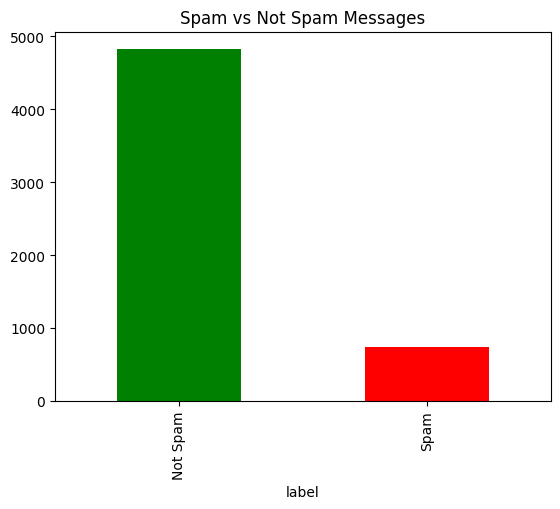

In [ ]:

# Install and import libraries
!pip -q install kagglehub

import kagglehub
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

# Load dataset
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
df = pd.read_csv(url, sep="\t", header=None, names=["label", "message"])

# Preprocess data
df["label"] = df["label"].map({"ham": 0, "spam": 1})

X = df["message"]
y = df["label"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Convert text into numerical features
vectorizer = CountVectorizer(stop_words="english")
X_train = vectorizer.fit_transform(X_train)
X_test = vectorizer.transform(X_test)

# Train Naive Bayes model
model = MultinomialNB()
model.fit(X_train, y_train)

# Predict and evaluate
predictions = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, predictions) * 100, "%")
print("\nClassification Report:")
print(classification_report(y_test, predictions))

# Test a new email
email = ["Congratulations! You have won a free prize. Claim now!"]
result = model.predict(vectorizer.transform(email))

print("Email Classification:",
      "Spam" if result[0] == 1 else "Not Spam")

import matplotlib.pyplot as plt
df["label"].map({0:"Not Spam", 1:"Spam"}).value_counts().plot(kind="bar", color=["green","red"])
plt.title("Spam vs Not Spam Messages")
plt.show()

